In [3]:
import math
import random


class ExactMDMallowsSampler:
    """
    Approximate two-parameter Mallows sampler over exact-MD profiles.

    Target weight:
        phi_m ** D_m * phi_w ** D_w

    where D_m and D_w are total Kendall-tau distances from the
    cyclic central MD profile.
    """

    def __init__(
        self,
        num_agents,
        phi_m,
        phi_w,
        seed=None,
        burn_in=None,
        steps_between=None,
    ):
        if num_agents < 1:
            raise ValueError("num_agents must be positive")

        if not 0 <= phi_m <= 1:
            raise ValueError("phi_m must be between 0 and 1")

        if not 0 <= phi_w <= 1:
            raise ValueError("phi_w must be between 0 and 1")

        self.n = num_agents
        self.phi_m = phi_m
        self.phi_w = phi_w
        self.rng = random.Random(seed)

        # Cyclic central profile, using internal labels 0,...,n-1.
        self.central_left = [
            [(man + rank) % self.n for rank in range(self.n)]
            for man in range(self.n)
        ]

        self.central_right = self._derive_right(self.central_left)

        self.current_left = [
            vote.copy() for vote in self.central_left
        ]
        self.current_right = [
            vote.copy() for vote in self.central_right
        ]

        self.current_dm = 0
        self.current_dw = 0

        if burn_in is None:
            burn_in = 200 * self.n * self.n

        if steps_between is None:
            steps_between = 20 * self.n

        self.steps_between = steps_between

        self._run_chain(burn_in)

    def _derive_right(self, votes_left):
        """Derive the women's rankings using exact rank complementarity."""
        votes_right = [[None] * self.n for _ in range(self.n)]

        for man in range(self.n):
            for rank, woman in enumerate(votes_left[man]):
                complementary_rank = self.n - 1 - rank
                votes_right[woman][complementary_rank] = man

        return votes_right

    @staticmethod
    def _kendall_distance(vote, central_vote):
        """Kendall-tau distance between two rankings."""
        central_position = {
            candidate: position
            for position, candidate in enumerate(central_vote)
        }

        order = [
            central_position[candidate]
            for candidate in vote
        ]

        distance = 0

        for i in range(len(order)):
            for j in range(i + 1, len(order)):
                if order[i] > order[j]:
                    distance += 1

        return distance

    def _total_distance(self, votes, central_votes):
        return sum(
            self._kendall_distance(vote, central_vote)
            for vote, central_vote in zip(votes, central_votes)
        )

    @staticmethod
    def _log_phi_power(phi, distance):
        """
        Return log(phi ** distance), including the phi=0 boundary.
        """
        if distance == 0:
            return 0.0

        if phi == 0:
            return -math.inf

        return distance * math.log(phi)

    def _log_weight(self, dm, dw):
        return (
            self._log_phi_power(self.phi_m, dm)
            + self._log_phi_power(self.phi_w, dw)
        )

    def _mcmc_step(self):
        """
        Propose an MD-preserving 2x2 Latin-square trade.

        Row and column pairs are sampled from a fixed symmetric proposal
        distribution, so no additional Hastings correction is needed.
        """
        if self.n < 2:
            return

        row1, row2 = self.rng.sample(range(self.n), 2)
        col1, col2 = self.rng.sample(range(self.n), 2)

        a = self.current_left[row1][col1]
        b = self.current_left[row1][col2]
        c = self.current_left[row2][col1]
        d = self.current_left[row2][col2]

        # A valid intercalate has the form:
        #
        #     a b
        #     b a
        #
        if a == b or a != d or b != c:
            return

        proposed_left = [
            vote.copy() for vote in self.current_left
        ]

        proposed_left[row1][col1], proposed_left[row1][col2] = (
            proposed_left[row1][col2],
            proposed_left[row1][col1],
        )

        proposed_left[row2][col1], proposed_left[row2][col2] = (
            proposed_left[row2][col2],
            proposed_left[row2][col1],
        )

        proposed_right = self._derive_right(proposed_left)

        proposed_dm = self._total_distance(
            proposed_left,
            self.central_left,
        )
        proposed_dw = self._total_distance(
            proposed_right,
            self.central_right,
        )

        current_log_weight = self._log_weight(
            self.current_dm,
            self.current_dw,
        )
        proposed_log_weight = self._log_weight(
            proposed_dm,
            proposed_dw,
        )

        log_acceptance_ratio = (
            proposed_log_weight - current_log_weight
        )

        if log_acceptance_ratio >= 0:
            accept = True
        elif log_acceptance_ratio == -math.inf:
            accept = False
        else:
            accept = (
                math.log(self.rng.random())
                < log_acceptance_ratio
            )

        if accept:
            self.current_left = proposed_left
            self.current_right = proposed_right
            self.current_dm = proposed_dm
            self.current_dw = proposed_dw

    def _run_chain(self, number_of_steps):
        for _ in range(number_of_steps):
            self._mcmc_step()

    def sample(self):
        """Return the next exact-MD profile using 1-based labels."""
        self._run_chain(self.steps_between)

        votes_left = [
            [candidate + 1 for candidate in vote]
            for vote in self.current_left
        ]

        votes_right = [
            [candidate + 1 for candidate in vote]
            for vote in self.current_right
        ]

        return [votes_left, votes_right]

In [1]:
%pip install mapel-marriages

  Using cached numpy-1.24.4-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.6 kB)
  Using cached scipy-1.10.1-cp311-cp311-macosx_12_0_arm64.whl.metadata (100 kB)
  Using cached gurobipy-10.0.3-cp311-cp311-macosx_10_9_universal2.whl.metadata (15 kB)
  Using cached prefsampling-0.1.15-py3-none-any.whl.metadata (7.4 kB)
Using cached prefsampling-0.1.15-py3-none-any.whl (62 kB)
Using cached gurobipy-10.0.3-cp311-cp311-macosx_10_9_universal2.whl (10.1 MB)
Using cached numpy-1.24.4-cp311-cp311-macosx_11_0_arm64.whl (13.8 MB)
Using cached scipy-1.10.1-cp311-cp311-macosx_12_0_arm64.whl (28.7 MB)
  Attempting uninstall: gurobipy
    Found existing installation: gurobipy 11.0.3
    Uninstalling gurobipy-11.0.3:
      Successfully uninstalled gurobipy-11.0.3
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: scipy━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/4 [numpy]
    Found existing ins

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import json
from req_functions_from_ApproxSP import *
from tqdm import tqdm
from generate_profiles import *
from euclidean import *
from mallows import *
from AccompliceManipulation import *
from impartial import *

**Accomplice Manipulation**

In [4]:
##Mallows MD

data_MD = []
numberMD = []
numberMD_pairs = []
n=10
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []

    for phi2 in tqdm(phi_list):
        count = []
        count_pairs = []

        sampler = ExactMDMallowsSampler(
            num_agents=n,
            phi_m=phi1,
            phi_w=phi2,
        )

        for samples in range(500):
            pref = sampler.sample()

            mpref = pref[0]
            wpref = pref[1]

            matching = gale_shapley(mpref, wpref)

            count_woman = 0
            cnt_pairs = 0

            for manipulator in range(1, n + 1):
                cnt = 0

                for accomplice in range(1, n + 1):
                    result = accomplice_manipulation(
                        mpref,
                        wpref,
                        manipulator,
                        accomplice,
                    )

                    if result[0] != matching:
                        cnt += 1

                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt

            count_pairs.append(cnt_pairs)
            count.append(count_woman)

            data_MD.append([
                phi1,
                phi2,
                json.dumps(mpref),
                json.dumps(wpref),
                samples,
                count_woman,
                cnt_pairs,
            ])

        number_phi.append(sum(count) / len(count))
        number_phi_pairs.append(
            sum(count_pairs) / len(count_pairs)
        )

    numberMD.append(number_phi)
    numberMD_pairs.append(number_phi_pairs) 
print(numberMD)
print(numberMD_pairs) 

100%|██████████| 6/6 [01:18<00:00, 13.14s/it]

[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]
[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]


In [5]:
df2 = pd.DataFrame(data_MD, columns=["phi_m", "phi_w", "mpref", "wpref", "sample", "count_woman", "count_pairs"])
df2.to_csv('mallows_MD_random(10).csv', index=False)

**Self Manipulation**

In [6]:
df = pd.read_csv('mallows_MD_random(10).csv')

self_manipulation_count = []
    
for i, row in df.iterrows():
    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])

    n = len(mpref)
    count = 0
    original_matching = gale_shapley(mpref, wpref)
    for manipulator in range(1, n + 1):
        manipulated_matching = self_manipulation(mpref, wpref, manipulator)
        if manipulated_matching[0] != original_matching:
            count += 1
    self_manipulation_count.append(count)

df['self_manipulating_women'] = self_manipulation_count
df.to_csv('mallows_MD_random(10).csv', index=False)

**Two-for-One**

In [7]:
import ast 

In [8]:
## Two for One Code

import itertools
import copy

def generate_sw_manipulations(w_pref):
    """
    Sw: Move any two distinct men to top of w's list in any order.
    """
    manipulations = []
    for mi, mj in itertools.permutations(w_pref, 2): 
        rest = [m for m in w_pref if m != mi and m != mj]
        new_pref = [mi, mj] + rest
        manipulations.append(new_pref)
    return manipulations


def generate_sm_manipulations(m_pref, mu_m):
    """
    Sm: Promote µ(m) to top, then for every other woman, promote her to top of that list.
    """
    sm = []
    bm = [mu_m] + [w for w in m_pref if w != mu_m]
    sm.append(bm)

    for w0 in bm[1:]:  # exclude mu(m) which is already at the top
        manipulated = [w0] + [w for w in bm if w != w0]
        sm.append(manipulated)

    return sm


def two_for_one(mpref, wpref, accomplice, beneficiary, initial_matching):
    #initial_matching = gale_shapley(mpref, wpref)
    mpref_prime = copy.deepcopy(mpref)
    wpref_prime = copy.deepcopy(wpref)
    best_matching = initial_matching

    accomplice_pref = mpref[accomplice - 1] 
    beneficiary_pref = wpref[beneficiary - 1]

    Sw = generate_sw_manipulations(beneficiary_pref)

    for w_misreport in Sw:
        #t5 = time.perf_counter()

        Sm = generate_sm_manipulations(accomplice_pref, initial_matching[accomplice - 1])

        for m_misreport in Sm:
            #t6 = time.perf_counter()
            mpref_prime[accomplice - 1] = m_misreport 
            wpref_prime[beneficiary - 1] = w_misreport
            new_matching = gale_shapley(mpref_prime, wpref_prime)

            new_w_pairing = new_matching[beneficiary - 1]
            new_m_pairing = new_matching[accomplice - 1]

            if beneficiary_pref.index(new_w_pairing) < beneficiary_pref.index(best_matching[beneficiary - 1]) and best_matching[accomplice - 1] == new_m_pairing:
                best_matching = new_matching
                accomplice_pref = m_misreport
                beneficiary_pref = w_misreport
        #t7 = time.perf_counter()
        #print(f"Time for t5 - t6: {t6 - t5:.4f} seconds")
        #print(f"Time for t6 - t7: {t7 - t6:.4f} seconds")
    return best_matching, accomplice_pref, beneficiary_pref

In [11]:
df = pd.read_csv("mallows_MD_random(10).csv")

results = []


for idx, row in tqdm(
    df.iterrows(),
    total=len(df),
):
    mpref = json.loads(row["mpref"])
    wpref = json.loads(row["wpref"])

    mpref = [
        [int(x) for x in preference]
        for preference in mpref
    ]
    wpref = [
        [int(x) for x in preference]
        for preference in wpref
    ]

    n = len(mpref)

    # Calculate the original matching for this profile.
    original_matching = gale_shapley(
        mpref,
        wpref,
    )

    instance_results = []

    # Continue with the manipulator/accomplice loops...

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_MD_random(10).csv', index=False)


100%|██████████| 18000/18000 [3:28:36<00:00,  1.44it/s]     


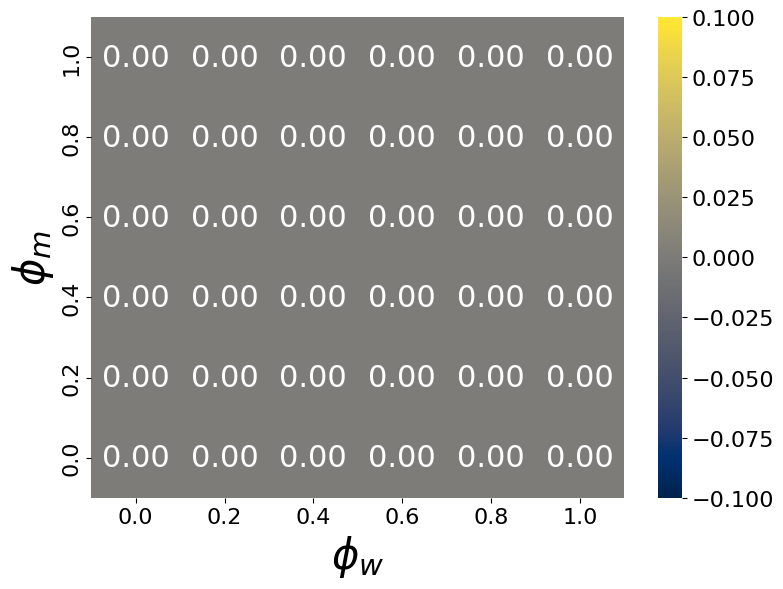

In [13]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_random(10).csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["self_manipulating_women"].mean().reset_index()

heatmap_data["self_manipulating_women"] = heatmap_data["self_manipulating_women"] 

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="self_manipulating_women")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_MD_random_self.pdf", format="pdf")
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_76944/3090004281.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')


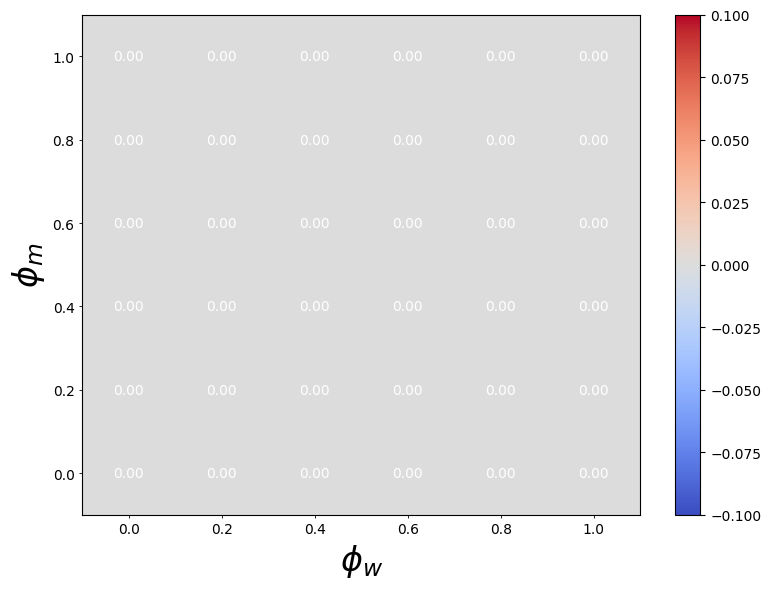

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("mallows_MD_random(10).csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_woman']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_woman'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_woman', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix / 10

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='coolwarm', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
#plt.title('Accomplice: Beneficiary Women', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
#plt.savefig("mallows_MD_acc_women_30.pdf", format='pdf')
plt.show()


In [15]:


import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_random(10).csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["two_for_one_results"].mean().reset_index()

heatmap_data["two_for_one_results"] = heatmap_data["two_for_one_results"] / 100

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="two_for_one_results")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
#plt.savefig("mallows_MD_two_for_one_30.pdf", format="pdf")
plt.show()


TypeError: agg function failed [how->mean,dtype->object]

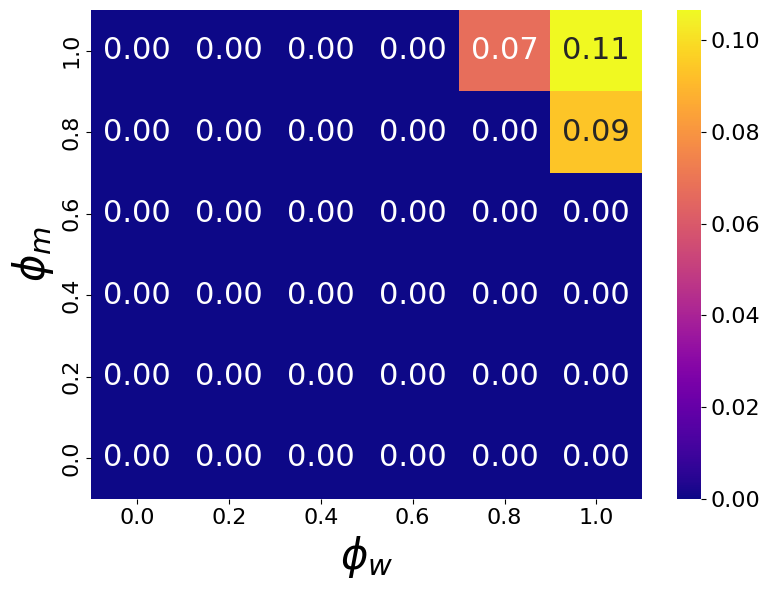

In [16]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("mallows_MD_random(10).csv")


def count_positive_pairs(cell):
    """Count manipulator-accomplice pairs having positive benefit."""
    if pd.isna(cell):
        return 0

    results = json.loads(cell)

    return sum(
        1
        for manipulator_results in results
        for accomplice_result in manipulator_results
        if accomplice_result[0] > 0
    )


df["positive_pair_count"] = (
    df["two_for_one_results"].apply(count_positive_pairs)
)

heatmap_data = (
    df.groupby(
        ["phi_m", "phi_w"],
        as_index=False,
    )["positive_pair_count"]
    .mean()
)

# There are n² possible manipulator-accomplice pairs.
n = len(json.loads(df.iloc[0]["mpref"]))
heatmap_data["positive_pair_proportion"] = (
    heatmap_data["positive_pair_count"] / (n * n)
)

pivot_table = heatmap_data.pivot(
    index="phi_m",
    columns="phi_w",
    values="positive_pair_proportion",
)

plt.figure(figsize=(8, 6))

ax = sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".2f",
    cmap="plasma",
    annot_kws={"size": 22},
)

plt.xlabel(r"$\phi_w$", fontsize=30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.show()

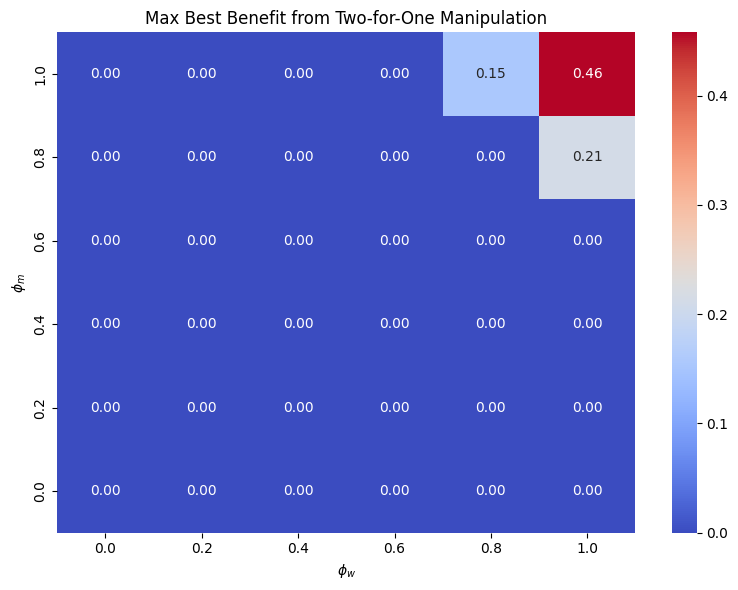

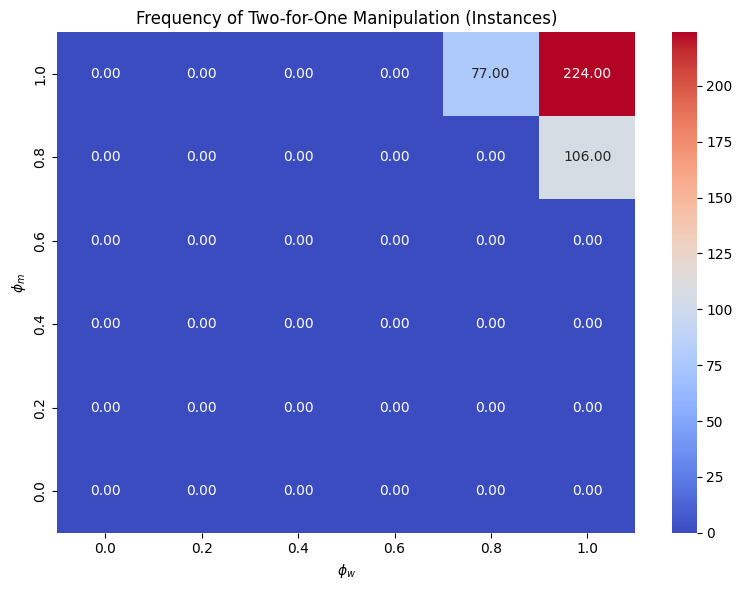

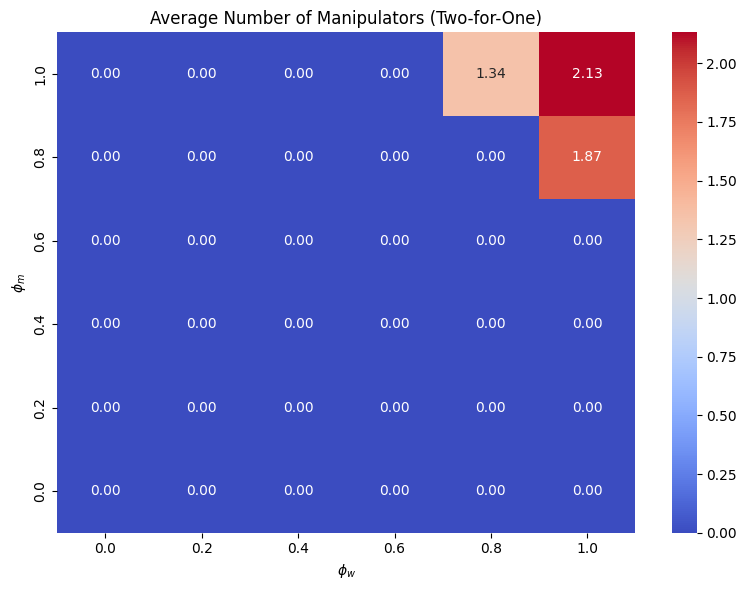

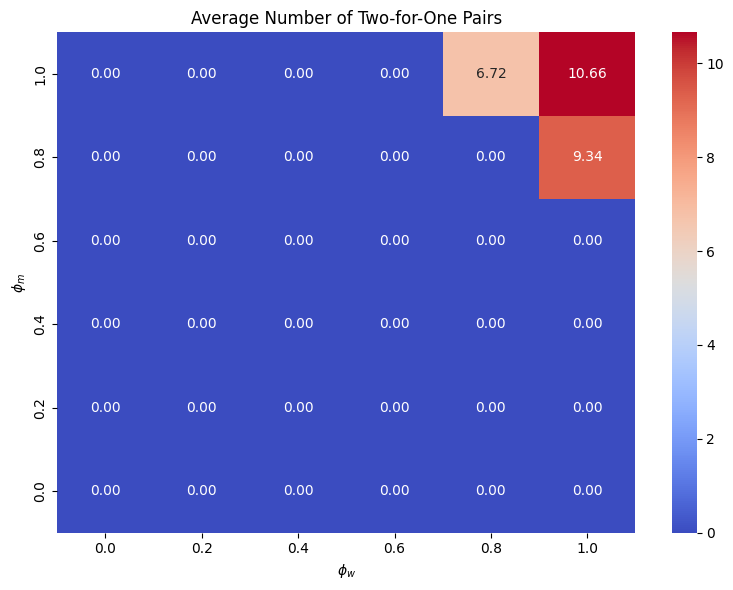

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MD_random(10).csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)
    
    
    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MD_random(10).csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Max Best Benefit from Two-for-One Manipulation", "mallows_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_number_two_pairs")


In [28]:
import random


def _ranks_to_pref(rank_vector):
    """Invert a rank vector into a preference order."""
    n = len(rank_vector)
    pref = [None] * n
    for k, r in enumerate(rank_vector):
        pref[r] = k
    return pref


def _pref_to_ranks(pref):
    n = len(pref)
    ranks = [None] * n
    for pos, item in enumerate(pref):
        ranks[item] = pos
    return ranks


def _cyclic_reference_latin_square(n):
    """Latin square underlying generate_asymmetric_votes (man i's rank of woman j)."""
    votes_left = [[(k + i + 1) % n for k in range(n)] for i in range(n)]
    return [_pref_to_ranks(votes_left[i]) for i in range(n)]


def _try_intercalate_swap(L, n, rng):
    """One attempted Latin-square-preserving 2x2 swap. Returns True if it succeeded."""
    i1, i2 = rng.sample(range(n), 2)
    j1, j2 = rng.sample(range(n), 2)
    a, b = L[i1][j1], L[i1][j2]
    if a != b and L[i2][j1] == b and L[i2][j2] == a:
        L[i1][j1], L[i1][j2] = b, a
        L[i2][j1], L[i2][j2] = a, b
        return True
    return False


def _mix_latin_square(L, n, phi, rng, attempts_scale=20):
    """phi=0: untouched reference. phi=1: heavily mixed toward random."""
    num_attempts = int(phi * attempts_scale * n * n)
    for _ in range(num_attempts):
        _try_intercalate_swap(L, n, rng)
    return L


def generate_md_votes(num_agents: int = None, phi: float = 0.0, seed=None, **kwargs):
    """
    Mutually-diagonal (MD) preference profile with dispersion parameter phi in [0,1],
    analogous to Mallows phi.

    phi=0 reproduces generate_asymmetric_votes exactly. Larger phi mixes the
    underlying Latin square via random intercalate swaps -> non-cyclic MD
    profiles, while the rank-complementarity condition holds exactly for
    every phi.
    """
    n = num_agents
    rng = random.Random(seed)
    L = _cyclic_reference_latin_square(n)
    L = _mix_latin_square(L, n, phi, rng)

    votes_left = [_ranks_to_pref(L[i]) for i in range(n)]
    col_ranks = [[n - 1 - L[i][j] for i in range(n)] for j in range(n)]
    votes_right = [_ranks_to_pref(col_ranks[j]) for j in range(n)]
    return [votes_left, votes_right]

In [ ]:
##Mallows MD

data_MD = []
numberMD = []
numberMD_pairs = []
n=10
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]
for phi1 in tqdm(phi_list):
    number_phi = []
    number_phi_pairs = []

    for phi2 in tqdm(phi_list):
        count = []
        count_pairs = []

        sampler = ExactMDMallowsSampler(
            num_agents=n,
            phi_m=phi1,
            phi_w=phi2,
        )

        for samples in range(500):
            pref = sampler.sample()

            mpref = pref[0]
            wpref = pref[1]

            matching = gale_shapley(mpref, wpref)

            count_woman = 0
            cnt_pairs = 0

            for manipulator in range(1, n + 1):
                cnt = 0

                for accomplice in range(1, n + 1):
                    result = accomplice_manipulation(
                        mpref,
                        wpref,
                        manipulator,
                        accomplice,
                    )

                    if result[0] != matching:
                        cnt += 1

                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt

            count_pairs.append(cnt_pairs)
            count.append(count_woman)

            data_MD.append([
                phi1,
                phi2,
                json.dumps(mpref),
                json.dumps(wpref),
                samples,
                count_woman,
                cnt_pairs,
            ])

        number_phi.append(sum(count) / len(count))
        number_phi_pairs.append(
            sum(count_pairs) / len(count_pairs)
        )

    numberMD.append(number_phi)
    numberMD_pairs.append(number_phi_pairs) 
print(numberMD)
print(numberMD_pairs) 